## 1. Hugging Face Login

#### This imports the token from Kaggle Secrets, so make sure the secret is set correctly before running the code.

In [1]:
import os
from huggingface_hub import login
from kaggle_secrets import UserSecretsClient

user_secrets = UserSecretsClient()
HF_TOKEN = user_secrets.get_secret("HF_TOKEN")
os.environ["HF_TOKEN"] = HF_TOKEN
login(token=HF_TOKEN)

print("Hugging Face login successful.")

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


Hugging Face login successful.


## 2. Check GPU

In [2]:
import torch

print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())
for i in range(torch.cuda.device_count()):
    print(f"GPU {i}:", torch.cuda.get_device_name(i))


def get_device():
    """
      Return the computing device used in the current session.
    """
    return torch.device("cuda" if torch.cuda.is_available() else "cpu")


DEVICE = get_device()
print("Using device:", DEVICE)
if DEVICE.type == "cuda":
    print(torch.cuda.get_device_name(0))


CUDA available: True
GPU count: 2
GPU 0: Tesla T4
GPU 1: Tesla T4
Using device: cuda
Tesla T4


In [3]:
# shutil.rmtree("/kaggle/working/cjpe_runs_fast")

## 4. Load Tokenizer

In [5]:
# %%writefile a1_tokenizer.py
"""Expose your Assignment-1 BPE implementation to Assignment 3.

Reuse your A-1 tokenizer code/class here. The important change is that it must be
RETRAINED on the `train_text` supplied by Assignment 3 rather than reusing a tokenizer
trained on the Assignment-1 dataset.
"""

''' Required returned interface:
      tokenizer.encode(text) -> sequence of integer ids
      tokenizer.decode(ids) -> string
      tokenizer.vocab_size OR tokenizer.get_vocab_size()'''
import re
from tqdm import tqdm
from collections import defaultdict, Counter

class ByteLevelBPE:
    def __init__(self, vocab_size=5000):
        self.vocab_size = vocab_size
        self.reserved = ["<pad>", "<unk>", "<s>", "</s>"]
        self.merges = []
        self.itos = list(self.reserved)
        self.stoi = {}
        self.ranks = {}
        self.merged_map = {}
        self._cache = {}
        # Regex pattern matching words, numbers, individual punctuation, and whitespace sequences
        pattern = r"""'s|'t|'re|'ve|'m|'ll|'d| ?[^\s\W\d_]+| ?\d+| ?[^\s\w]+|\s+(?!\S)|\s+"""
        self.pat = re.compile(pattern, re.UNICODE)
        
    def _split_text(self, text):
        """Splits text into chunks preserving whitespace, or falls back to basic regex split."""
        pattern = r"""'s|'t|'re|'ve|'m|'ll|'d| ?[^\s\W\d_]+| ?\d+| ?[^\s\w]+|\s+(?!\S)|\s+"""
        return re.findall(pattern, str(text), flags=re.UNICODE)

    def fit(self, texts, max_unique_words=200000):
        """Train a byte-level BPE tokenizer using inverted indexing for fast merging."""
        raw_counts = Counter()
        iterator = [texts] if isinstance(texts, str) else texts

        # Preserve whitespace tokens when populating initial raw_counts
        for text in tqdm(iterator, desc="Building word vocabulary"):
            for chunk in self._split_text(text):
                raw_counts[chunk] += 1

        if max_unique_words and len(raw_counts) > max_unique_words:
            most_common = raw_counts.most_common(max_unique_words)
            raw_counts = dict(most_common)

        word_freqs = {}
        pair_counts = defaultdict(int)
        pair_to_words = defaultdict(set)

        for word, count in raw_counts.items():
            encoded = word.encode("utf-8")
            byte_word = tuple(encoded[i:i+1] for i in range(len(encoded)))
            word_freqs[byte_word] = count

            for i in range(len(byte_word) - 1):
                pair = (byte_word[i], byte_word[i + 1])
                pair_counts[pair] += count
                pair_to_words[pair].add(byte_word)

        base_bytes = sorted({token for word in word_freqs for token in word})
        self.itos = list(self.reserved) + base_bytes
        self.merges = []

        target_merges = self.vocab_size - len(self.itos)

        with tqdm(total=target_merges, desc="Training BPE Merges") as pbar:
            while len(self.itos) < self.vocab_size:
                if not pair_counts:
                    break

                best_pair = max(pair_counts, key=lambda p: (pair_counts[p], p[0], p[1]))
                if pair_counts[best_pair] <= 0:
                    break

                merged_token = best_pair[0] + best_pair[1]
                self.merges.append((best_pair, merged_token))
                self.itos.append(merged_token)

                words_to_update = list(pair_to_words[best_pair])
                del pair_counts[best_pair]
                del pair_to_words[best_pair]

                p0, p1 = best_pair

                for word in words_to_update:
                    count = word_freqs.get(word, 0)
                    if count == 0:
                        continue

                    new_word = []
                    i = 0
                    n = len(word)

                    while i < n:
                        if i + 1 < n and word[i] == p0 and word[i + 1] == p1:
                            new_word.append(merged_token)
                            i += 2
                        else:
                            new_word.append(word[i])
                            i += 1

                    new_word = tuple(new_word)

                    for j in range(len(word) - 1):
                        old_p = (word[j], word[j + 1])
                        if old_p in pair_counts:
                            pair_counts[old_p] -= count
                            if pair_counts[old_p] <= 0:
                                del pair_counts[old_p]

                    for j in range(len(new_word) - 1):
                        new_p = (new_word[j], new_word[j + 1])
                        pair_counts[new_p] += count
                        pair_to_words[new_p].add(new_word)

                    del word_freqs[word]
                    word_freqs[new_word] = count

                pbar.update(1)

        self.vocab_size = len(self.itos)
        self.stoi = {token: idx for idx, token in enumerate(self.itos)}
        self.ranks = {pair: rank for rank, (pair, _) in enumerate(self.merges)}
        self.merged_map = {pair: merged for pair, merged in self.merges}
        self._cache = {}
        return self

    def encode_word(self, word):
        """Encode single word using memoization and local pair updates."""
        if word in self._cache:
            return self._cache[word]

        encoded = word.encode("utf-8")
        tokens = [encoded[i:i+1] for i in range(len(encoded))]

        if len(tokens) <= 1:
            res = [self.stoi.get(token, self.stoi["<unk>"]) for token in tokens]
            self._cache[word] = res
            return res

        while len(tokens) > 1:
            min_rank = float("inf")
            min_pair = None

            for i in range(len(tokens) - 1):
                pair = (tokens[i], tokens[i + 1])
                rank = self.ranks.get(pair, float("inf"))
                if rank < min_rank:
                    min_rank = rank
                    min_pair = pair

            if min_pair is None or min_rank == float("inf"):
                break

            merged = self.merged_map[min_pair]
            new_tokens = []
            i = 0
            n = len(tokens)
            p0, p1 = min_pair

            while i < n:
                if i + 1 < n and tokens[i] == p0 and tokens[i + 1] == p1:
                    new_tokens.append(merged)
                    i += 2
                else:
                    new_tokens.append(tokens[i])
                    i += 1
            tokens = new_tokens

        res = [self.stoi.get(token, self.stoi["<unk>"]) for token in tokens]
        self._cache[word] = res
        return res

    def encode(self, text):
        """Encode a sentence while preserving original spaces and newlines."""
        ids = [self.stoi["<s>"]]
        for chunk in self._split_text(text):
            ids.extend(self.encode_word(chunk))
        ids.append(self.stoi["</s>"])
        return ids

    def decode(self, ids):
        """Decode BPE token IDs back into text seamlessly."""
        byte_list = []
        for idx in ids:
            if 0 <= idx < len(self.itos):
                tok = self.itos[idx]
            else:
                tok = "<unk>"
            if tok not in self.reserved and isinstance(tok, bytes):
                byte_list.append(tok)
        try:
            return b"".join(byte_list).decode("utf-8", errors="ignore")
        except Exception:
            return ""

    def get_vocab_size(self):
        return self.vocab_size

def train_tokenizer(train_text: str, vocab_size: int):
    """Train A-1 BPE tokenizer on `train_text` and return the trained tokenizer."""
    tokenizer = ByteLevelBPE(vocab_size)
    tokenizer.fit(train_text)
    return tokenizer

## 9. Define The Model

## LMConfig

In [6]:
@dataclass
class LMConfig:
    # ---- general ----
    vocab_size: int = VOCAB_SIZE
    max_seq_len: int = MODEL_CONTEXT_LENGTH
    d_model: int = N_EMBD
    n_layers: int = N_LAYER
    dropout: float = 0.0
    bias: bool = False
    tie_embeddings: bool = True
    norm_type: str = "rmsnorm"          # "rmsnorm" | "layernorm"
    norm_eps: float = 1e-6

    # ---- positional ----
    pos_emb_type: str = "rope"          # "rope" | "sinusoidal"
    rope_theta: float = 10000.0

    # ---- attention ----
    attn_type: str = "gqa"              # "gqa" | "mla"
    n_heads: int = N_HEAD
    # GQA (n_kv_heads == n_heads -> MHA, 1 -> MQA)
    n_kv_heads: int = 2
    head_dim: Optional[int] = None      # defaults to d_model // n_heads
    # MLA
    q_lora_rank: Optional[int] = 256    # None -> no query compression
    kv_lora_rank: int = 128
    qk_nope_head_dim: int = 48
    qk_rope_head_dim: int = 16
    v_head_dim: int = 64

    # ---- feed-forward ----
    ffn_type: str = "dense"             # "dense" | "moe"
    d_ff: int = 2048
    # MoE
    n_experts: int = 8
    top_k: int = 2
    n_shared_experts: int = 1
    expert_d_ff: int = 512
    aux_loss_coef: float = 0.01
    first_k_dense_layers: int = 0       # first k layers stay dense
    moe_layer_freq: int = 1             # after that, every n-th layer is MoE

    def __post_init__(self):
        assert self.norm_type in ("rmsnorm", "layernorm")
        assert self.pos_emb_type in ("rope", "sinusoidal")
        assert self.attn_type in ("gqa", "mla")
        assert self.ffn_type in ("dense", "moe")

        if self.pos_emb_type == "sinusoidal":
            assert self.d_model % 2 == 0, "sinusoidal needs even d_model"

        if self.attn_type == "gqa":
            if self.head_dim is None:
                assert self.d_model % self.n_heads == 0, "d_model must be divisible by n_heads"
                self.head_dim = self.d_model // self.n_heads
            assert self.n_heads % self.n_kv_heads == 0, "n_heads must be divisible by n_kv_heads"
            if self.pos_emb_type == "rope":
                assert self.head_dim % 2 == 0, "RoPE needs even head_dim"
        else:
            if self.pos_emb_type == "rope":
                assert self.qk_rope_head_dim % 2 == 0 and self.qk_rope_head_dim > 0

        if self.ffn_type == "moe":
            assert 1 <= self.top_k <= self.n_experts

    @property
    def rope_dim(self) -> int:
        return self.qk_rope_head_dim if self.attn_type == "mla" else self.head_dim

    def is_moe_layer(self, layer_idx: int) -> bool:
        if self.ffn_type != "moe" or layer_idx < self.first_k_dense_layers:
            return False
        return (layer_idx - self.first_k_dense_layers) % self.moe_layer_freq == 0

## Normalization layers

In [7]:
class RMSNorm(nn.Module):
    def __init__(self, dim: int, eps: float = 1e-6):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(dim))

    def forward(self, x):
        dtype = x.dtype
        x = x.float()
        x = x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps)
        return (x * self.weight.float()).to(dtype)


def make_norm(cfg: LMConfig, dim: int) -> nn.Module:
    if cfg.norm_type == "rmsnorm":
        return RMSNorm(dim, cfg.norm_eps)
    return nn.LayerNorm(dim, eps=cfg.norm_eps)

## Positional embeddings (RoPE and sinusoidal)

In [8]:
class RoPE(nn.Module):
    """Rotary embedding. Rotates q and k of shape (B, H, T, dim)."""

    def __init__(self, dim: int, max_seq_len: int, theta: float = 10000.0):
        super().__init__()
        inv_freq = 1.0 / (theta ** (torch.arange(0, dim, 2).float() / dim))
        t = torch.arange(max_seq_len).float()
        freqs = torch.outer(t, inv_freq)               # (L, dim/2)
        emb = torch.cat([freqs, freqs], dim=-1)        # (L, dim)
        self.register_buffer("cos", emb.cos(), persistent=False)
        self.register_buffer("sin", emb.sin(), persistent=False)

    @staticmethod
    def _rotate_half(x):
        x1, x2 = x.chunk(2, dim=-1)
        return torch.cat([-x2, x1], dim=-1)

    def rotate(self, x, positions):
        cos, sin = self.cos[positions], self.sin[positions]
        if cos.dim() == 2:                              # positions: (T,)
            cos, sin = cos[None, None], sin[None, None]
        else:                                           # positions: (B, T)
            cos, sin = cos[:, None], sin[:, None]
        cos, sin = cos.to(x.dtype), sin.to(x.dtype)
        return x * cos + self._rotate_half(x) * sin

    def forward(self, q, k, positions):
        return self.rotate(q, positions), self.rotate(k, positions)


class SinusoidalPositionalEmbedding(nn.Module):
    """Fixed sin/cos table, added to token embeddings once at model level."""

    def __init__(self, d_model: int, max_seq_len: int):
        super().__init__()
        pos = torch.arange(max_seq_len).float().unsqueeze(1)
        div = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe = torch.zeros(max_seq_len, d_model)
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer("pe", pe, persistent=False)

    def forward(self, x, offset: int = 0):
        T = x.size(1)
        return x + self.pe[offset:offset + T].to(x.dtype)

## Attention helper and GQA

In [9]:
def causal_sdpa(q, k, v, dropout_p: float = 0.0, training: bool = False):
    """Causal attention that also works when k/v are longer than q (KV cache)."""
    Tq, Tk = q.size(2), k.size(2)
    p = dropout_p if training else 0.0
    if Tq == Tk:
        return F.scaled_dot_product_attention(q, k, v, dropout_p=p, is_causal=True)
    if Tq == 1:
        return F.scaled_dot_product_attention(q, k, v, dropout_p=p)
    mask = torch.ones(Tq, Tk, dtype=torch.bool, device=q.device).tril(diagonal=Tk - Tq)
    return F.scaled_dot_product_attention(q, k, v, attn_mask=mask, dropout_p=p)


def masked_sdpa(q, k, v, attn_mask, dropout_p=0.0, training=False):
    if attn_mask is None:
        return causal_sdpa(q, k, v, dropout_p, training)            # training path unchanged
    return F.scaled_dot_product_attention(q, k, v, attn_mask=attn_mask,
                                          dropout_p=dropout_p if training else 0.0)

class GQAttention(nn.Module):
    """Grouped-query attention. cache = (k, v), each (B, n_kv_heads, T, head_dim)."""

    def __init__(self, cfg: LMConfig):
        super().__init__()
        self.n_heads, self.n_kv, self.hd = cfg.n_heads, cfg.n_kv_heads, cfg.head_dim
        self.q_proj = nn.Linear(cfg.d_model, self.n_heads * self.hd, bias=cfg.bias)
        self.k_proj = nn.Linear(cfg.d_model, self.n_kv * self.hd, bias=cfg.bias)
        self.v_proj = nn.Linear(cfg.d_model, self.n_kv * self.hd, bias=cfg.bias)
        self.o_proj = nn.Linear(self.n_heads * self.hd, cfg.d_model, bias=cfg.bias)
        self.dropout = cfg.dropout

    def forward(self, x, rope=None, positions=None, kv_cache=None, attn_mask=None):
        B, T, _ = x.shape
        q = self.q_proj(x).view(B, T, self.n_heads, self.hd).transpose(1, 2)
        k = self.k_proj(x).view(B, T, self.n_kv, self.hd).transpose(1, 2)
        v = self.v_proj(x).view(B, T, self.n_kv, self.hd).transpose(1, 2)
        if rope is not None:
            q, k = rope(q, k, positions)
        if kv_cache is not None:
            k = torch.cat([kv_cache[0], k], dim=2)
            v = torch.cat([kv_cache[1], v], dim=2)
        new_cache = (k, v)
        rep = self.n_heads // self.n_kv
        out = masked_sdpa(q, k.repeat_interleave(rep, dim=1), v.repeat_interleave(rep, dim=1),
                          attn_mask, self.dropout, self.training)
        out = out.transpose(1, 2).reshape(B, T, self.n_heads * self.hd)
        return self.o_proj(out), new_cache

## MLA

In [10]:
class MLAttention(nn.Module):
    """
    Multi-head Latent Attention (DeepSeek-style, un-absorbed version).
    cache = (latent (B, 1, T, kv_lora_rank), k_rope (B, 1, T, rope_dim) or None).
    Only the compressed latent and the small shared k_rope are cached.
    With sinusoidal positions the decoupled RoPE part is dropped (rope_dim = 0).
    """

    def __init__(self, cfg: LMConfig):
        super().__init__()
        self.H = cfg.n_heads
        self.dn = cfg.qk_nope_head_dim
        self.dr = cfg.qk_rope_head_dim if cfg.pos_emb_type == "rope" else 0
        self.dv = cfg.v_head_dim
        self.dropout = cfg.dropout

        q_out = self.H * (self.dn + self.dr)
        if cfg.q_lora_rank:
            self.q_down = nn.Linear(cfg.d_model, cfg.q_lora_rank, bias=cfg.bias)
            self.q_norm = make_norm(cfg, cfg.q_lora_rank)
            self.q_up = nn.Linear(cfg.q_lora_rank, q_out, bias=False)
            self.q_proj = None
        else:
            self.q_proj = nn.Linear(cfg.d_model, q_out, bias=cfg.bias)

        self.kv_down = nn.Linear(cfg.d_model, cfg.kv_lora_rank, bias=cfg.bias)
        self.kv_norm = make_norm(cfg, cfg.kv_lora_rank)
        self.kv_up = nn.Linear(cfg.kv_lora_rank, self.H * (self.dn + self.dv), bias=False)
        self.k_rope_proj = nn.Linear(cfg.d_model, self.dr, bias=cfg.bias) if self.dr > 0 else None
        self.o_proj = nn.Linear(self.H * self.dv, cfg.d_model, bias=cfg.bias)

    def forward(self, x, rope=None, positions=None, kv_cache=None, attn_mask=None):
        B, T, _ = x.shape
        q = self.q_up(self.q_norm(self.q_down(x))) if self.q_proj is None else self.q_proj(x)
        q = q.view(B, T, self.H, self.dn + self.dr).transpose(1, 2)
        latent = self.kv_norm(self.kv_down(x)).unsqueeze(1)
        k_rope = None
        if self.dr > 0:
            q_nope, q_rope = q.split([self.dn, self.dr], dim=-1)
            k_rope = self.k_rope_proj(x).unsqueeze(1)
            q_rope, k_rope = rope(q_rope, k_rope, positions)
        else:
            q_nope = q
        if kv_cache is not None:
            latent = torch.cat([kv_cache[0], latent], dim=2)
            if k_rope is not None:
                k_rope = torch.cat([kv_cache[1], k_rope], dim=2)
        new_cache = (latent, k_rope)
        Tk = latent.size(2)
        kv = self.kv_up(latent.squeeze(1)).view(B, Tk, self.H, self.dn + self.dv).transpose(1, 2)
        k_nope, v = kv.split([self.dn, self.dv], dim=-1)
        if self.dr > 0:
            q_full = torch.cat([q_nope, q_rope], dim=-1)
            k_full = torch.cat([k_nope, k_rope.expand(-1, self.H, -1, -1)], dim=-1)
        else:
            q_full, k_full = q_nope, k_nope
        out = masked_sdpa(q_full, k_full, v, attn_mask, self.dropout, self.training)
        out = out.transpose(1, 2).reshape(B, T, self.H * self.dv)
        return self.o_proj(out), new_cache


ATTN_REGISTRY = {"gqa": GQAttention, "mla": MLAttention}

## Feed-forward networks (GeLU)

In [11]:
class DenseFFN(nn.Module):
    """Linear -> GeLU -> Linear. Returns (out, aux_loss=0)."""

    def __init__(self, cfg: LMConfig, d_ff: Optional[int] = None):
        super().__init__()
        d_ff = d_ff or cfg.d_ff
        self.fc1 = nn.Linear(cfg.d_model, d_ff, bias=cfg.bias)
        self.act = nn.GELU()
        self.fc2 = nn.Linear(d_ff, cfg.d_model, bias=cfg.bias)

    def forward(self, x):
        return self.fc2(self.act(self.fc1(x))), x.new_zeros(())


class MoEFFN(nn.Module):
    """Top-k routed experts (DenseFFN each) + optional always-on shared experts."""

    def __init__(self, cfg: LMConfig):
        super().__init__()
        self.E, self.k = cfg.n_experts, cfg.top_k
        self.router = nn.Linear(cfg.d_model, self.E, bias=False)
        self.experts = nn.ModuleList([DenseFFN(cfg, cfg.expert_d_ff) for _ in range(self.E)])
        self.shared = nn.ModuleList([DenseFFN(cfg, cfg.expert_d_ff) for _ in range(cfg.n_shared_experts)])

    def forward(self, x):
        B, T, D = x.shape
        flat = x.reshape(-1, D)                                  # (N, D)

        probs = self.router(flat).float().softmax(dim=-1)        # (N, E)
        topv, topi = probs.topk(self.k, dim=-1)                  # (N, k)
        topv = topv / topv.sum(dim=-1, keepdim=True)             # renormalise

        out = torch.zeros_like(flat)
        for e, expert in enumerate(self.experts):
            tok_idx, slot = (topi == e).nonzero(as_tuple=True)
            if tok_idx.numel() == 0:
                continue
            y, _ = expert(flat[tok_idx])
            w = topv[tok_idx, slot].unsqueeze(-1).to(y.dtype)
            out.index_add_(0, tok_idx, (y * w).to(out.dtype))

        for sh in self.shared:
            out = out + sh(flat)[0]

        # Switch-style load-balancing loss: E * sum_i f_i * P_i
        if self.training:
            f = F.one_hot(topi, self.E).sum(dim=1).float().mean(dim=0) / self.k
            P = probs.mean(dim=0)
            aux = self.E * (f * P).sum()
        else:
            aux = x.new_zeros(())
        return out.view(B, T, D), aux


FFN_REGISTRY = {"dense": DenseFFN, "moe": MoEFFN}

## TransformerBlock

In [12]:
class TransformerBlock(nn.Module):
    def __init__(self, cfg: LMConfig, layer_idx: int):
        super().__init__()
        self.norm1 = make_norm(cfg, cfg.d_model)
        self.attn = ATTN_REGISTRY[cfg.attn_type](cfg)
        self.norm2 = make_norm(cfg, cfg.d_model)
        self.ffn = FFN_REGISTRY["moe" if cfg.is_moe_layer(layer_idx) else "dense"](cfg)
        self.drop = nn.Dropout(cfg.dropout)

    def forward(self, x, rope=None, positions=None, kv_cache=None, attn_mask=None):
        a, new_cache = self.attn(self.norm1(x), rope, positions, kv_cache, attn_mask)
        x = x + self.drop(a)
        f, aux = self.ffn(self.norm2(x))
        x = x + self.drop(f)
        return x, aux, new_cache

## DecoderLM

In [13]:
class DecoderLM(nn.Module):
    def __init__(self, cfg: LMConfig):
        super().__init__()
        self.cfg = cfg
        self.tok_emb = nn.Embedding(cfg.vocab_size, cfg.d_model)
        self.sin_emb = (SinusoidalPositionalEmbedding(cfg.d_model, cfg.max_seq_len)
                        if cfg.pos_emb_type == "sinusoidal" else None)
        self.rope = (RoPE(cfg.rope_dim, cfg.max_seq_len, cfg.rope_theta)
                     if cfg.pos_emb_type == "rope" else None)
        self.drop = nn.Dropout(cfg.dropout)
        self.blocks = nn.ModuleList([TransformerBlock(cfg, i) for i in range(cfg.n_layers)])
        self.final_norm = make_norm(cfg, cfg.d_model)
        self.lm_head = nn.Linear(cfg.d_model, cfg.vocab_size, bias=False)
        if cfg.tie_embeddings:
            self.lm_head.weight = self.tok_emb.weight

        self.apply(self._init_weights)
        # scaled init on residual output projections
        for name, p in self.named_parameters():
            if name.endswith("o_proj.weight") or name.endswith("fc2.weight"):
                nn.init.normal_(p, mean=0.0, std=0.02 / math.sqrt(2 * cfg.n_layers))

    @staticmethod
    def _init_weights(m):
        if isinstance(m, nn.Linear):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)
            if m.bias is not None:
                nn.init.zeros_(m.bias)
        elif isinstance(m, nn.Embedding):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)

    def forward(self, input_ids, targets=None, kv_caches=None, use_cache=False,
                last_only=False, attention_mask=None):
        B, T = input_ids.shape
        past = 0 if kv_caches is None else kv_caches[0][0].size(2)
        dev = input_ids.device
        if attention_mask is None:                                      # training / unpadded: unchanged behaviour
            assert past + T <= self.cfg.max_seq_len, "sequence exceeds max_seq_len"
            positions = torch.arange(past, past + T, device=dev)        # (T,)
            attn_mask = None
        else:
            am = attention_mask.to(dev).bool()
            assert am.shape == (B, past + T), f"attention_mask must be (B, past+T) = {(B, past + T)}"
            positions = (am.long().cumsum(-1) - 1).clamp(min=0)[:, past:]            # (B, T) per-row positions
            q_idx = torch.arange(past, past + T, device=dev)[:, None]
            k_idx = torch.arange(past + T, device=dev)[None, :]
            # causal AND key is a real token; the diagonal is always allowed so padded query rows never become all -inf
            attn_mask = ((k_idx <= q_idx)[None, None] & am[:, None, None, :]) | (k_idx == q_idx)[None, None]
    
        x = self.tok_emb(input_ids)
        if self.sin_emb is not None:
            x = x * math.sqrt(self.cfg.d_model) + self.sin_emb.pe[positions].to(x.dtype)
        x = self.drop(x)
    
        aux_total = x.new_zeros(())
        new_caches = []
        for i, block in enumerate(self.blocks):
            cache_i = None if kv_caches is None else kv_caches[i]
            x, aux, new_cache = block(x, self.rope, positions, cache_i, attn_mask)
            aux_total = aux_total + aux
            new_caches.append(new_cache)
    
        x = self.final_norm(x)
        if last_only:
            x = x[:, -1:, :]
        logits = self.lm_head(x)
        loss = None
        if targets is not None:
            ce = F.cross_entropy(logits.reshape(-1, logits.size(-1)).float(), targets.reshape(-1), ignore_index=-100)
            loss = ce + self.cfg.aux_loss_coef * aux_total
        caches = new_caches if (use_cache or kv_caches is not None) else None
        return logits, loss, caches

    @torch.no_grad()
    def generate(self, input_ids, attention_mask=None, max_new_tokens=400, temperature=0.4, top_k=50, top_p=0.9,
                 repetition_penalty=1.1, rep_window=256, no_repeat_ngram=0, ban_ids=(), pad_id=0, 
                 tokenizer=None, target_words=None, check_every=16):
        """input_ids: (B, L) LEFT-padded; attention_mask: (B, L) with 1 for real tokens, 0 for padding."""
        was_training = self.training
        self.eval()
        B, L = input_ids.shape
        dev = input_ids.device
        attn = (torch.ones(B, L, dtype=torch.long, device=dev) if attention_mask is None
                else attention_mask.to(dev).long())
        assert int(attn.sum(1).max()) + max_new_tokens <= self.cfg.max_seq_len, \
            "longest prompt + new tokens exceed max_seq_len"
        ban = torch.tensor(sorted(set(ban_ids)), dtype=torch.long, device=dev) if len(ban_ids) else None
    
        n = no_repeat_ngram
        seen = [dict() for _ in range(B)]
        hist = [[] for _ in range(B)]
    
        gen = input_ids.new_zeros((B, 0))
        done = torch.zeros(B, dtype=torch.bool, device=dev)
        caches, cur = None, input_ids
        for step in range(max_new_tokens):
            logits, _, caches = self(cur, kv_caches=caches, use_cache=True, last_only=True, attention_mask=attn)
            logits = logits[:, -1, :].float()
            if ban is not None:
                logits[:, ban] = float("-inf")
            if repetition_penalty != 1.0 and gen.size(1) > 0:
                recent = gen[:, -rep_window:]
                sc = torch.gather(logits, 1, recent)
                sc = torch.where(sc > 0, sc / repetition_penalty, sc * repetition_penalty)
                logits.scatter_(1, recent, sc)
            if n > 1:
                for b in range(B):
                    if len(hist[b]) >= n - 1:
                        banned = seen[b].get(tuple(hist[b][-(n - 1):]))
                        if banned:
                            logits[b, list(banned)] = float("-inf")
    
            if temperature <= 0:
                nxt = logits.argmax(dim=-1, keepdim=True)
            else:
                logits = logits / temperature
                if top_k:
                    kth = torch.topk(logits, min(top_k, logits.size(-1))).values[:, -1, None]
                    logits = logits.masked_fill(logits < kth, float("-inf"))
                if top_p and top_p < 1.0:
                    sl, si = torch.sort(logits, descending=True, dim=-1)
                    pr = torch.softmax(sl, dim=-1)
                    sl = sl.masked_fill(pr.cumsum(-1) - pr > top_p, float("-inf"))
                    logits = torch.full_like(logits, float("-inf")).scatter(1, si, sl)
                nxt = torch.multinomial(torch.softmax(logits, dim=-1), 1)
    
            nxt = torch.where(done.unsqueeze(1), torch.full_like(nxt, pad_id), nxt)
            if n > 1:
                for b, t in enumerate(nxt.squeeze(1).tolist()):
                    h = hist[b]
                    if len(h) >= n - 1:
                        seen[b].setdefault(tuple(h[-(n - 1):]), set()).add(t)
                    h.append(t)
            gen = torch.cat([gen, nxt], dim=1)
            cur = nxt
            attn = torch.cat([attn, torch.ones(B, 1, dtype=attn.dtype, device=dev)], dim=1)   # new token is a real token
    
            if target_words is not None and (step + 1) % check_every == 0:
                for b in torch.nonzero(~done).flatten().tolist():
                    if len(tokenizer.decode(gen[b].tolist()).split()) > target_words:
                        done[b] = True
                if done.all():
                    break
        self.train(was_training)
        return torch.cat([input_ids, gen], dim=1)

# Phase 4

In [2]:
# shutil.rmtree("/kaggle/working/phase1-models")

In [3]:
# !cp -rv ../input/datasets/pritam0289/phase1-models/ ./ 

'../input/datasets/pritam0289/phase1-models/' -> './phase1-models'
'../input/datasets/pritam0289/phase1-models/tokenizer.pkl' -> './phase1-models/tokenizer.pkl'
'../input/datasets/pritam0289/phase1-models/best_models' -> './phase1-models/best_models'
'../input/datasets/pritam0289/phase1-models/best_models/abl_mla_rope_moe_best.pt' -> './phase1-models/best_models/abl_mla_rope_moe_best.pt'
'../input/datasets/pritam0289/phase1-models/best_models/abl_mla_sin_moe_best.pt' -> './phase1-models/best_models/abl_mla_sin_moe_best.pt'
'../input/datasets/pritam0289/phase1-models/best_models/abl_gqa_rope_moe_best.pt' -> './phase1-models/best_models/abl_gqa_rope_moe_best.pt'
'../input/datasets/pritam0289/phase1-models/best_models/abl_gqa_sin_moe_best.pt' -> './phase1-models/best_models/abl_gqa_sin_moe_best.pt'


In [14]:
import pickle
with open("./phase1-models/tokenizer.pkl", "rb") as f:
        tokenizer = pickle.load(f)

### Cell 1: Imports and config

In [53]:
import os, re, json, math, time, copy, random, pickle, zipfile, gc, contextlib, shutil
import multiprocessing as mp
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset
from torch.utils.checkpoint import checkpoint
from huggingface_hub import hf_hub_download
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, precision_score, recall_score, confusion_matrix, roc_auc_score

for need in ["LMConfig", "DecoderLM", "ByteLevelBPE", "MoEFFN"]:
    assert need in globals(), f"Run the Phase-1 cell that defines {need} first"

SEED = 42
def seed_all(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_all()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"
HF_TOKEN = globals().get("HF_TOKEN") or os.environ.get("HF_TOKEN")
PHASE1_DIR = "/kaggle/working/phase1-models"
CKPT_P1 = f"{PHASE1_DIR}/best_models"
OUT = "/kaggle/working/cjpe_runs"
RES_DIR, PROB_DIR, CKPT_DIR, PLOT_DIR = [f"{OUT}/{d}" for d in ("res", "probs", "ckpt", "plots")]
for d in (OUT, RES_DIR, PROB_DIR, CKPT_DIR, PLOT_DIR): os.makedirs(d, exist_ok=True)

VARIANTS = ["gqa_rope_moe", "mla_rope_moe", "gqa_sin_moe", "mla_sin_moe"]
BASE_VARIANT = "mla_rope_moe"      # architecture used for ablations / technique comparison / KD
CHUNK = 512                         # tokens per chunk (incl. BOS)
HC = 12000                          # chars kept from head and from tail of each judgment
STUDENT_KEEP = [0, 5, 10, 15]       # KD student = these 4 pretrained blocks of the 16
ADA_TARGET = 0.5                    # AdaLoRA final rank budget fraction

# Compute profile. T4 ~10k tok/s => 1 doc (K=4) ~ 0.2 s per epoch.
PROFILE = "full"                # "fast" | "balanced" | "full"
PROF = dict(
    fast=dict(tech_docs=2000, abl_docs=800,  dev_docs=500,  ep_tech=2, ep_abl=2),
    balanced=dict(tech_docs=4000, abl_docs=1500, dev_docs=1000, ep_tech=3, ep_abl=2),
    full=dict(tech_docs=None, abl_docs=3000, dev_docs=None, ep_tech=1, ep_abl=2),
)[PROFILE]

# ---- mixed precision (T4 -> fp16 + GradScaler) ----
def get_amp():
    if DEVICE.type != "cuda": return None, False
    return (torch.bfloat16, False) if torch.cuda.get_device_capability(0)[0] >= 8 else (torch.float16, True)
AMP_DTYPE, USE_SCALER = get_amp()
def amp(): return torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=AMP_DTYPE is not None)

# ---- Phase-1 architectures (must match training) ----
BASE = dict(vocab_size=30000, max_seq_len=2048, d_model=768, n_layers=16, n_heads=8, n_kv_heads=2,
            dropout=0.0, bias=False, tie_embeddings=True, d_ff=2048, q_lora_rank=384, kv_lora_rank=192,
            qk_nope_head_dim=80, qk_rope_head_dim=16, v_head_dim=96)
MOE = dict(ffn_type="moe", first_k_dense_layers=2, n_experts=8, top_k=2, n_shared_experts=1,
           expert_d_ff=512, aux_loss_coef=0.01)
CONFIGS = {
    "gqa_rope_moe": LMConfig(**BASE, **MOE, attn_type="gqa", pos_emb_type="rope"),
    "mla_rope_moe": LMConfig(**BASE, **MOE, attn_type="mla", pos_emb_type="rope"),
    "gqa_sin_moe":  LMConfig(**BASE, **MOE, attn_type="gqa", pos_emb_type="sinusoidal"),
    "mla_sin_moe":  LMConfig(**BASE, **MOE, attn_type="mla", pos_emb_type="sinusoidal"),
}

if "tokenizer" not in globals() or not hasattr(tokenizer, "stoi"):
    with open(f"{PHASE1_DIR}/tokenizer.pkl", "rb") as f: tokenizer = pickle.load(f)
PAD, BOS = tokenizer.stoi["<pad>"], tokenizer.stoi["<s>"]

def load_phase1(variant):
    ck = torch.load(f"{CKPT_P1}/abl_{variant}_best.pt", map_location="cpu", weights_only=False)
    sd = ck["model"] if isinstance(ck, dict) and "model" in ck else ck
    lm = DecoderLM(CONFIGS[variant])
    lm.load_state_dict({k.replace("_orig_mod.", ""): v for k, v in sd.items()}, strict=True)
    return lm

print("device", DEVICE, "| amp", AMP_DTYPE, "| scaler", USE_SCALER, "| profile", PROFILE, PROF)

device cuda | amp torch.float16 | scaler True | profile full {'tech_docs': None, 'abl_docs': 3000, 'dev_docs': None, 'ep_tech': 1, 'ep_abl': 2}


### Cell 2: Load data and EDA

Phase_4_CJPE/Train/train.json: reconstructing file:   0%|          |  0.00B /  737MB            

Phase_4_CJPE/Train/train.json: downloading bytes:           |  0.00B            

Phase_4_CJPE/Train/dev.json: reconstructing file:   0%|          |  0.00B / 45.0MB            

Phase_4_CJPE/Train/dev.json: downloading bytes:           |  0.00B            

Phase_4_CJPE/Test/test.json: reconstructing file:   0%|          |  0.00B / 35.3MB            

Phase_4_CJPE/Test/test.json: downloading bytes:           |  0.00B            

37387 1988 1517


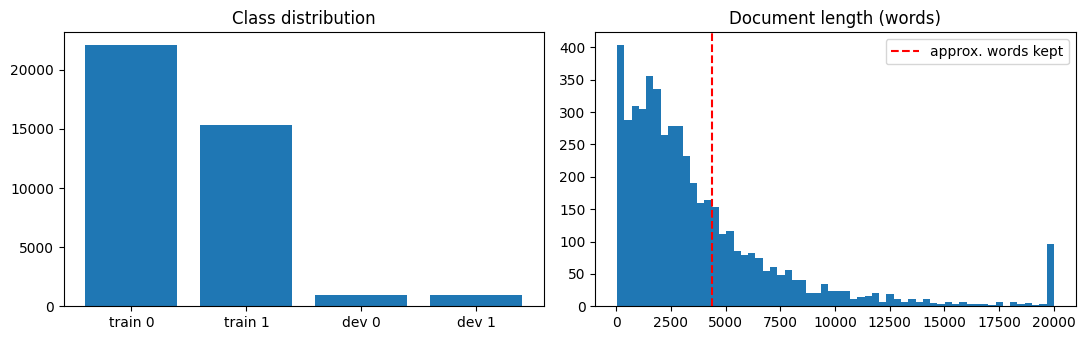

train label ratio: [0.5902319 0.4097681] | median words: 2662.0


In [16]:
def hf(name):
    return hf_hub_download(HF_DATASET_REPO, f"Phase_4_CJPE/{name}", repo_type="dataset", token=HF_TOKEN)

raw_train = json.load(open(hf("Train/train.json"), encoding="utf-8"))
raw_dev   = json.load(open(hf("Train/dev.json"), encoding="utf-8"))
raw_test  = json.load(open(hf("Test/test.json"), encoding="utf-8"))
print(len(raw_train), len(raw_dev), len(raw_test))

def strat_sample(items, n, key, seed=SEED):
    """Class-ratio preserving subsample (keeps natural imbalance)."""
    if n is None or n >= len(items): return items
    rng = random.Random(seed); by = {}
    for r in items: by.setdefault(key(r), []).append(r)
    out = []
    for k, v in by.items(): out += rng.sample(v, min(len(v), round(n * len(v) / len(items))))
    rng.shuffle(out); return out

# ---- EDA ----
ytr = np.array([int(r["label"]) for r in raw_train])
ydv = np.array([int(r["label"]) for r in raw_dev])
lens = np.array([len(r["text"].split()) for r in raw_train[:5000]])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].bar(["train 0", "train 1", "dev 0", "dev 1"], [(ytr==0).sum(), (ytr==1).sum(), (ydv==0).sum(), (ydv==1).sum()])
ax[0].set_title("Class distribution")
ax[1].hist(np.clip(lens, 0, 20000), bins=60)
ax[1].axvline(2*HC/5.5, c="r", ls="--", label="approx. words kept")
ax[1].set_title("Document length (words)")
ax[1].legend()
plt.tight_layout()
plt.savefig(f"{PLOT_DIR}/eda.png", dpi=150)
plt.show()
print("train label ratio:", np.bincount(ytr) / len(ytr), "| median words:", np.median(lens))

### Cell 3: Tokenization (head and tail clipping, cached) and chunking

In [17]:
def _clip(t):
    if len(t) <= 2 * HC: return t, ""
    h, tl = t[:HC], t[-HC:]
    i = h.rfind(" "); h = h[:i] if i > 0 else h
    j = tl.find(" "); tl = tl[j + 1:] if j >= 0 else tl
    return h, tl

def _tok(t):
    h, tl = _clip(t)
    ids = tokenizer.encode(h)[1:-1]
    if tl: ids = ids + tokenizer.encode(tl)[1:-1]
    return np.asarray(ids, dtype=np.int32)

def tokenize_all(raw, tag):
    path = f"{OUT}/tok_{tag}_{len(raw)}_{HC}.pkl"
    if os.path.exists(path): return pickle.load(open(path, "rb"))
    texts = [re.sub(r"\s+", " ", r["text"]).strip() for r in raw]
    with mp.get_context("fork").Pool(os.cpu_count() or 2) as pool:
        ids = list(tqdm(pool.imap(_tok, texts, chunksize=8), total=len(texts), desc=f"tokenize {tag}"))
    recs = [dict(id=str(r["id"]), ids=i, nw=len(t.split()),
                 y=int(r["label"]) if r.get("label") is not None else -1)
            for r, i, t in zip(raw, ids, texts)]
    pickle.dump(recs, open(path, "wb")); return recs

tr_raw  = strat_sample(raw_train, PROF["tech_docs"], key=lambda r: int(r["label"]))
dev_raw = strat_sample(raw_dev,   PROF["dev_docs"],  key=lambda r: int(r["label"]))
train_recs = tokenize_all(tr_raw, "train")
dev_recs   = tokenize_all(dev_raw, "dev")
test_recs  = tokenize_all(raw_test, "test")
abl_recs   = strat_sample(train_recs, PROF["abl_docs"], key=lambda r: r["y"])
ydev = np.array([r["y"] for r in dev_recs])
print(len(train_recs), len(abl_recs), len(dev_recs), len(test_recs))
print("mean tokens/doc:", np.mean([len(r["ids"]) for r in train_recs]))

# ---- chunk selection strategies over the token stream ----
def get_chunks(ids, strategy, K, U=CHUNK - 1):
    n = len(ids)
    if n <= U: return [ids]
    fwd = [(i, min(i + U, n)) for i in range(0, n, U)]
    bwd = [(max(0, e - U), e) for e in range(n, 0, -U)]
    if strategy == "head": spans = fwd[:K]
    elif strategy == "tail": spans = bwd[:K][::-1]
    elif strategy == "headtail":
        hs = fwd[:K - K // 2]; ts = [s for s in bwd[:K // 2][::-1] if s[0] >= hs[-1][1]]
        spans = hs + ts
    elif strategy == "uniform":
        idx = np.unique(np.linspace(0, len(fwd) - 1, min(K, len(fwd))).round().astype(int))
        spans = [fwd[i] for i in idx]
    else: raise ValueError(strategy)
    return [ids[a:b] for a, b in spans]

class DocDS(Dataset):
    def __init__(self, recs, strategy, K): self.recs, self.s, self.K = recs, strategy, K
    def __len__(self): return len(self.recs)
    def __getitem__(self, i):
        r = self.recs[i]
        ch = [np.concatenate([[BOS], c]).astype(np.int64) for c in get_chunks(r["ids"], self.s, self.K)]
        return i, ch, r["y"]

def collate(b):
    B, Km = len(b), max(len(x[1]) for x in b); T = max(len(c) for x in b for c in x[1])
    ids = torch.full((B, Km, T), PAD, dtype=torch.long); cm = torch.zeros(B, Km, dtype=torch.bool)
    for i, (_, chs, _) in enumerate(b):
        for j, c in enumerate(chs): ids[i, j, :len(c)] = torch.from_numpy(c); cm[i, j] = True
    return torch.tensor([x[0] for x in b]), ids, cm, torch.tensor([x[2] for x in b])

tokenize dev:   0%|          | 0/1988 [00:00<?, ?it/s]

37387 3000 1988 1517
mean tokens/doc: 2741.2710032899136


### Cell 4: PEFT modules (LoRA, LoRMA, AdaLoRA-lite, Adapter, BitFit)

In [18]:
class LoRALinear(nn.Module):             # W x + s * B A x
    def __init__(s, base, r=8, alpha=16):
        super().__init__(); s.base, s.scale = base, alpha / r
        s.A = nn.Parameter(torch.randn(r, base.in_features) / math.sqrt(base.in_features))
        s.B = nn.Parameter(torch.zeros(base.out_features, r))
    def forward(s, x): return s.base(x) + (x @ s.A.t() @ s.B.t()) * s.scale

class LoRMALinear(nn.Module):            # multiplicative: (I + s*BA) W x
    def __init__(s, base, r=8, alpha=16):
        super().__init__(); s.base, s.scale = base, alpha / r
        s.A = nn.Parameter(torch.randn(r, base.out_features) / math.sqrt(base.out_features))
        s.B = nn.Parameter(torch.zeros(base.out_features, r))
    def forward(s, x):
        y = s.base(x); return y + (y @ s.A.t() @ s.B.t()) * s.scale

class AdaLoRALinear(nn.Module):          # simplified AdaLoRA: W x + s * P diag(E) Q x, global importance pruning
    def __init__(s, base, r=12, alpha=24):
        super().__init__(); s.base, s.r, s.scale = base, r, alpha / r
        s.P = nn.Parameter(nn.init.orthogonal_(torch.empty(base.out_features, r)))
        s.Q = nn.Parameter(nn.init.orthogonal_(torch.empty(r, base.in_features)))
        s.E = nn.Parameter(torch.zeros(r))
        s.register_buffer("mask", torch.ones(r)); s.register_buffer("imp", torch.zeros(r))
    def forward(s, x): return s.base(x) + (((x @ s.Q.t()) * (s.E * s.mask)) @ s.P.t()) * s.scale
    def orth(s):
        I = torch.eye(s.r, device=s.P.device)
        return ((s.P.t() @ s.P - I) ** 2).sum() + ((s.Q @ s.Q.t() - I) ** 2).sum()

def adalora_update(model, step, total):
    mods = [m for m in model.modules() if isinstance(m, AdaLoRALinear)]
    if not mods: return
    for m in mods:
        if m.E.grad is not None: m.imp.mul_(0.85).add_(0.15 * (m.E.detach() * m.E.grad).abs())
    ti, tf = int(0.15 * total), int(0.75 * total)
    if step < ti: return
    prog = min(1.0, (step - ti) / max(1, tf - ti))
    init = len(mods) * mods[0].r; tgt = int(init * ADA_TARGET)
    b = int(tgt + (init - tgt) * (1 - prog) ** 3)
    allimp = torch.cat([m.imp for m in mods])
    thr = torch.topk(allimp, b).values[-1] if b < len(allimp) else allimp.min() - 1
    for m in mods: m.mask.copy_((m.imp >= thr).float())

class BiasLinear(nn.Module):             # Phase-1 has bias=False, so BitFit adds zero-init trainable biases
    def __init__(s, base):
        super().__init__(); s.base = base; s.bias = nn.Parameter(torch.zeros(base.out_features))
    def forward(s, x): return s.base(x) + s.bias

class Adapter(nn.Module):
    def __init__(s, d, r):
        super().__init__(); s.down, s.up = nn.Linear(d, r), nn.Linear(r, d)
        nn.init.zeros_(s.up.weight); nn.init.zeros_(s.up.bias)
    def forward(s, x): return x + s.up(F.gelu(s.down(x)))

def wrap(module, fn, names=None, skip_names=(), skip_dirs=()):
    for n, c in list(module.named_children()):
        if n in skip_dirs: continue
        if isinstance(c, nn.Linear) and n not in skip_names and (names is None or n in names):
            setattr(module, n, fn(c))
        else: wrap(c, fn, names, skip_names, skip_dirs)

ATTN_T = {"q_proj", "k_proj", "v_proj", "o_proj", "q_down", "q_up", "kv_down", "kv_up", "k_rope_proj"}

### Cell 5: Hierarchical document classifier

In [19]:
def _blk(block, x, rope, pos, mask):
    y, aux, _ = block(x, rope, pos, None, mask); return y, aux

class DocBackbone(nn.Module):
    def __init__(s, lm, causal=False, adapter_dim=0, grad_ckpt=True):
        super().__init__(); s.lm, s.causal, s.grad_ckpt, s.no_grad = lm, causal, grad_ckpt, False
        s.adapters = nn.ModuleList([Adapter(lm.cfg.d_model, adapter_dim) for _ in lm.blocks]) if adapter_dim else None
    def _fwd(s, ids, mask):
        lm = s.lm; pos = torch.arange(ids.size(1), device=ids.device)
        x = lm.tok_emb(ids)
        if lm.sin_emb is not None: x = x * math.sqrt(lm.cfg.d_model) + lm.sin_emb.pe[pos].to(x.dtype)
        am = None if s.causal else mask[:, None, None, :]
        aux = x.new_zeros(()); use_ck = s.grad_ckpt and s.training and torch.is_grad_enabled()
        for i, b in enumerate(lm.blocks):
            if use_ck: x, a = checkpoint(_blk, b, x, lm.rope, pos, am, use_reentrant=False)
            else: x, a = _blk(b, x, lm.rope, pos, am)
            aux = aux + a
            if s.adapters is not None: x = s.adapters[i](x)
        return lm.final_norm(x), aux
    def forward(s, ids, mask):
        with (torch.no_grad() if s.no_grad else contextlib.nullcontext()): return s._fwd(ids, mask)

class DocClassifier(nn.Module):
    """ids [B,K,T] -> chunk embeddings (masked mean) -> doc pooling -> head."""
    def __init__(s, lm, pool="attn", head="mlp", causal=False, adapter_dim=0, grad_ckpt=True, max_chunks=16, drop=0.1):
        super().__init__()
        s.backbone = DocBackbone(lm, causal, adapter_dim, grad_ckpt); D = lm.cfg.d_model; s.pool = pool
        if pool in ("attn", "hier"):
            s.att = nn.Sequential(nn.Linear(D, 256), nn.Tanh(), nn.Linear(256, 1))
        if pool == "hier":
            s.pos = nn.Embedding(max_chunks, D)
            s.hier = nn.TransformerEncoder(nn.TransformerEncoderLayer(D, 8, 1024, 0.1, batch_first=True, norm_first=True), 1)
        s.drop = nn.Dropout(drop)
        s.head = nn.Linear(D, 2) if head == "linear" else nn.Sequential(nn.Linear(D, D // 2), nn.GELU(), nn.Dropout(drop), nn.Linear(D // 2, 2))
    def forward(s, ids, cm):
        B, K, T = ids.shape; D = s.backbone.lm.cfg.d_model
        flat = ids[cm]; tm = flat != PAD
        h, aux = s.backbone(flat, tm)
        m = tm.unsqueeze(-1).to(h.dtype); e = (h * m).sum(1) / m.sum(1).clamp(min=1)
        E = e.new_zeros(B, K, D); E[cm] = e; E = E.float(); cmf = cm.unsqueeze(-1).float()
        if s.pool == "hier":
            E = s.hier(E + s.pos(torch.arange(K, device=E.device)).float(), src_key_padding_mask=~cm).float()
        if s.pool in ("attn", "hier"):
            w = s.att(E).squeeze(-1).float().masked_fill(~cm, -1e4).softmax(-1).unsqueeze(-1)
            d = (w * E).sum(1)
        elif s.pool == "mean": d = (E * cmf).sum(1) / cmf.sum(1)
        elif s.pool == "max":  d = E.masked_fill(~cm.unsqueeze(-1), -1e4).max(1).values
        elif s.pool == "last": d = E[torch.arange(B, device=E.device), cm.sum(1) - 1]
        return s.head(s.drop(d)).float(), d.float(), aux

def build(spec):
    lm = load_phase1(spec["variant"]); m = spec["method"]; ad = 0
    if spec.get("student"):
        lm.blocks = nn.ModuleList([lm.blocks[i] for i in STUDENT_KEEP])
        lm.cfg = copy.copy(lm.cfg); lm.cfg.n_layers = len(STUDENT_KEEP)
    if m not in ("full", "kd", "kd_control"):
        for p in lm.parameters(): p.requires_grad = False
    if m == "partial":
        for b in lm.blocks[-3:]:
            for p in b.parameters(): p.requires_grad = True
        for p in lm.final_norm.parameters(): p.requires_grad = True
    elif m == "bitfit":
        wrap(lm.blocks, BiasLinear, skip_names={"router"})
        for n, p in lm.named_parameters():
            if "norm" in n: p.requires_grad = True
    elif m == "lora":    wrap(lm.blocks, lambda b: LoRALinear(b, 8, 16), ATTN_T, skip_dirs={"experts", "shared"})
    elif m == "lorma":   wrap(lm.blocks, lambda b: LoRMALinear(b, 8, 16), ATTN_T, skip_dirs={"experts", "shared"})
    elif m == "adalora": wrap(lm.blocks, lambda b: AdaLoRALinear(b, 12, 24), ATTN_T, skip_dirs={"experts", "shared"})
    elif m == "adapter": ad = 64
    model = DocClassifier(lm, spec["pool"], spec["head"], spec["causal"], ad)
    return model.to(DEVICE)

def count_params(model):
    return sum(p.numel() for p in model.parameters()), sum(p.numel() for p in model.parameters() if p.requires_grad)

### Cell 6: Training, inference, metrics

In [47]:
def mf1(y, p, t=0.5): return f1_score(y, (p >= t).astype(int), average="macro")
def best_thr(y, p):
    ts = np.linspace(0.05, 0.95, 91); sc = [mf1(y, p, t) for t in ts]; i = int(np.argmax(sc))
    return float(ts[i]), float(sc[i])
def probs(lg): return F.softmax(lg, -1)[:, 1].numpy()

@torch.no_grad()
# @torch.no_grad()
# def infer(model, recs, strategy, K, bs=None, desc=None):
#     print("Loading data usinbg DataLoader....")
#     model.eval()
#     dl = DataLoader(DocDS(recs, strategy, K), batch_size=bs or max(1, 16 // K),
#                                   shuffle=False, collate_fn=collate, num_workers=2)
#     print("Loading done")
#     L, E = [], []
#     i = 0
#     for _, ids, cm, _ in tqdm(dl, desc=desc, disable=desc is None, leave=False):
#         if i % 100 == 0:
#             print(i)
#         i+= 1
#         with amp(): lg, em, _ = model(ids.to(DEVICE), cm.to(DEVICE))
#         L.append(lg.float().cpu()); E.append(em.float().cpu())
#     return torch.cat(L), torch.cat(E)
def infer(model, recs, strategy, K, bs=None):
    print("Loading data usinbg DataLoader....")
    model.eval(); dl = DataLoader(DocDS(recs, strategy, K), batch_size=bs or max(1, 16 // K),
                                  shuffle=False, collate_fn=collate, num_workers=2)
    L, E = [], []
    for _, ids, cm, _ in tqdm(dl):
        with amp(): lg, em, _ = model(ids.to(DEVICE), cm.to(DEVICE))
        L.append(lg.float().cpu()); E.append(em.float().cpu())
    return torch.cat(L), torch.cat(E)

def snap(model, full):
    sd = model.state_dict()
    if full: keys = list(sd)
    else:
        tn = {n for n, p in model.named_parameters() if p.requires_grad}
        keys = [k for k in sd if k in tn or k.endswith(".mask")]
    return {k: sd[k].detach().cpu().clone() for k in keys}

def set_gradual(model, ep):
    lm = model.backbone.lm; n = len(lm.blocks)
    k = [0, max(1, n // 4), max(1, n // 2), n][min(ep, 3)]
    if k > 0:
        for b in lm.blocks[-k:]:
            for p in b.parameters(): p.requires_grad = True
        for p in lm.final_norm.parameters(): p.requires_grad = True
    model.backbone.no_grad = (k == 0)


SAVE_EVERY = 100   # optimizer steps between mid-epoch checkpoints (effective batch = 8 docs)

def ydev_of(recs): return np.array([r["y"] for r in recs])

def _atomic_save(obj, path):
    tmp = path + ".tmp"; torch.save(obj, tmp); os.replace(tmp, path)

def fit(model, name, tr_recs, dv_recs, *, method, epochs, lr, head_lr=1e-3, strategy, K,
        class_weight=True, kd=None, wd=0.01, resume=True):
    mbs = max(1, 32 // K); accum = max(1, 32 // mbs)               # effective batch = 8 docs
    n = len(tr_recs); nb_total = math.ceil(n / mbs)               # micro-batches per epoch
    steps_per_ep = math.ceil(nb_total / accum)
    total = epochs * steps_per_ep; warm = max(1, int(0.06 * total))
    ytr = np.array([r["y"] for r in tr_recs])
    cw = torch.tensor(n / (2 * np.bincount(ytr, minlength=2)), dtype=torch.float, device=DEVICE) if class_weight else None
    if method == "probe": model.backbone.no_grad = True
    if method == "gradual": set_gradual(model, 0)

    bb = [p for nm, p in model.named_parameters() if nm.startswith("backbone.") and (p.requires_grad or method == "gradual")]
    hd = [p for nm, p in model.named_parameters() if not nm.startswith("backbone.")]
    groups = ([dict(params=bb, base=lr)] if bb else []) + [dict(params=hd, base=head_lr)]
    opt = torch.optim.AdamW(groups, weight_decay=wd)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_SCALER)
    ada = [m for m in model.modules() if isinstance(m, AdaLoRALinear)]
    full_snap = method in ("full", "gradual", "kd", "kd_control")
    aux_c = model.backbone.lm.cfg.aux_loss_coef

    last_p, best_p = f"{CKPT_DIR}/{name}_last.pt", f"{CKPT_DIR}/{name}_bestsd.pt"
    start_ep, skip_b, gstep, best_f, hist = 0, 0, 0, -1.0, []
    carry_loss, carry_nb = 0.0, 0
    if resume and os.path.exists(last_p):
        st = torch.load(last_p, map_location="cpu", weights_only=False)
        model.load_state_dict({k: v.to(DEVICE) for k, v in st["model"].items()}, strict=False)
        opt.load_state_dict(st["opt"])
        if st.get("scaler") and USE_SCALER: scaler.load_state_dict(st["scaler"])
        start_ep, skip_b, gstep = st["epoch"], st["batch"], st["gstep"]
        best_f, hist = st["best_f"], st["hist"]; carry_loss, carry_nb = st["tl"], st["nb"]
        torch.set_rng_state(st["rng_cpu"]);
        if DEVICE.type == "cuda": torch.cuda.set_rng_state(st["rng_cuda"])
        del st; gc.collect()
        print(f"[{name}] RESUMED at epoch {start_ep+1}/{epochs}, batch {skip_b}/{nb_total}, step {gstep}/{total}, best F1 {best_f:.4f}")
        if start_ep >= epochs:
            print(f"[{name}] training already complete, loading best state")

    def save_last(ep, batch, tl, nb):
        _atomic_save(dict(model=snap(model, full_snap), opt=opt.state_dict(),
                          scaler=scaler.state_dict() if USE_SCALER else None,
                          epoch=ep, batch=batch, gstep=gstep, best_f=best_f, hist=hist, tl=tl, nb=nb,
                          rng_cpu=torch.get_rng_state(),
                          rng_cuda=torch.cuda.get_rng_state() if DEVICE.type == "cuda" else None), last_p)

    ds = DocDS(tr_recs, strategy, K)
    for ep in range(start_ep, epochs):
        if method == "gradual": set_gradual(model, ep)
        model.train(); t0 = time.time()
        order = np.random.RandomState(SEED + ep).permutation(n).tolist()   # deterministic per-epoch shuffle
        first_b = skip_b if ep == start_ep else 0
        tl, nb = (carry_loss, carry_nb) if (ep == start_ep and first_b > 0) else (0.0, 0)
        loader = DataLoader(Subset(ds, order[first_b * mbs:]), batch_size=mbs, shuffle=False,
                            collate_fn=collate, num_workers=2)
        opt.zero_grad(set_to_none=True)
        for bi, (idx, ids, cm, y) in enumerate(tqdm(loader, desc=f"{name} ep{ep+1}/{epochs}", leave=False)):
            b = first_b + bi                                           # absolute micro-batch index in the epoch
            ids, cm, y = ids.to(DEVICE), cm.to(DEVICE), y.to(DEVICE)
            with amp(): lg, emb, aux = model(ids, cm)
            ce = F.cross_entropy(lg.float(), y, weight=cw)
            if kd is not None:
                T = kd["T"]; tlg = kd["logits"][idx].to(DEVICE); tem = kd["emb"][idx].to(DEVICE)
                klv = F.kl_div(F.log_softmax(lg.float() / T, -1), F.softmax(tlg / T, -1), reduction="batchmean") * T * T
                cosl = 1 - F.cosine_similarity(emb.float(), tem, dim=-1).mean()
                loss = kd["alpha"] * ce + (1 - kd["alpha"]) * klv + kd["beta"] * cosl
            else: loss = ce
            loss = loss + aux_c * aux.float()
            if ada: loss = loss + 0.1 * sum(m.orth() for m in ada) / len(ada)
            scaler.scale(loss / accum).backward(); tl += float(loss.detach()); nb += 1
            if (b + 1) % accum == 0 or b + 1 == nb_total:
                f = (gstep + 1) / warm if gstep < warm else 0.1 + 0.45 * (1 + math.cos(math.pi * (gstep - warm) / max(1, total - warm)))
                for g in opt.param_groups: g["lr"] = g["base"] * f
                scaler.unscale_(opt)
                torch.nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], 1.0)
                if method == "adalora": adalora_update(model, gstep, total)
                scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True); gstep += 1
                if gstep % SAVE_EVERY == 0 and b + 1 < nb_total:       # mid-epoch checkpoint
                    save_last(ep, b + 1, tl, nb)
        # ---- end of epoch: evaluate, keep best, checkpoint ----
        yd = ydev_of(dv_recs)
        lgd, _ = infer(model, dv_recs, strategy, K); pd_ = probs(lgd)
        auc = roc_auc_score(yd, pd_); f05 = mf1(yd, pd_)
        dloss = F.cross_entropy(lgd, torch.tensor(yd), weight=cw.cpu() if cw is not None else None).item()
        hist.append(dict(epoch=ep + 1, train_loss=tl / max(1, nb), dev_auc=float(auc), dev_loss=dloss,
                         dev_f1_05=float(f05), dev_f1_tuned=best_thr(yd, pd_)[1], sec=time.time() - t0))
        print(f"[{name}] ep{ep+1} loss {tl/max(1,nb):.4f} | dev loss {dloss:.4f} AUC {auc:.4f} F1@0.5 {f05:.4f}")
        if auc > best_f:                                   # best_f now tracks AUROC
            best_f = auc; _atomic_save(snap(model, full_snap), best_p)
        save_last(ep + 1, 0, 0.0, 0)
        carry_loss, carry_nb = 0.0, 0

    model.load_state_dict({k: v.to(DEVICE) for k, v in torch.load(best_p, map_location="cpu", weights_only=False).items()}, strict=False)
    best_state = torch.load(best_p, map_location="cpu", weights_only=False)
    return hist, best_state

### Cell 7: Experiment runner (cached, resumable)

In [45]:
RES = {}
for fn in os.listdir(RES_DIR):
    if fn.endswith(".json"): RES[fn[:-5]] = json.load(open(f"{RES_DIR}/{fn}"))
print("cached runs:", list(RES))

LR = dict(probe=0, full=3e-5, partial=1e-4, gradual=1e-4, bitfit=1e-3, lora=1e-3, lorma=1e-3,
          adalora=1e-3, adapter=1e-3, kd=5e-5, kd_control=5e-5)
def spec_of(variant, method, **kw):
    d = dict(variant=variant, method=method, pool="attn", head="mlp", causal=False, strategy="headtail", K=4, student=False)
    d.update(kw); return d

def load_model(name):
    m = build(RES[name]["spec"]); m.load_state_dict(torch.load(RES[name]["ckpt"], map_location=DEVICE), strict=False)
    return m.eval()

def crossfit_f1(y, p, seed=0):
    rng = np.random.RandomState(seed); idx = rng.permutation(len(y)); a, b = idx[:len(y)//2], idx[len(y)//2:]
    out = []
    for tr, te in ((a, b), (b, a)):
        t, _ = best_thr(y[tr], p[tr]); out.append(mf1(y[te], p[te], t))
    return float(np.mean(out))

@torch.no_grad()
def teacher_cache(name, recs):
    
    sp = RES[name]["spec"];
    t = load_model(name)
    print("OK")
    lg, em = infer(t, recs, sp["strategy"], sp["K"], bs=max(1, 32 // sp["K"]))
    del t; gc.collect(); torch.cuda.empty_cache(); return lg, em

def run(name, spec, *, group, train_set, epochs, test=True, class_weight=True, kd=None):
    if name in RES: print(f"[{name}] cached  F1={RES[name]['f1_tuned']:.4f}"); return RES[name]
    seed_all(); model = build(spec); tot, trn = count_params(model)
    print(f"\n=== {name} | total {tot/1e6:.1f}M trainable {trn/1e6:.2f}M ({100*trn/tot:.2f}%)")
    if DEVICE.type == "cuda": torch.cuda.reset_peak_memory_stats()
    t0 = time.time()
    hist, best = fit(model, name, train_set, dev_recs, method=spec["method"], epochs=epochs, lr=LR[spec["method"]],
                     strategy=spec["strategy"], K=spec["K"], class_weight=class_weight, kd=kd)
    train_sec = time.time() - t0
    peak = torch.cuda.max_memory_allocated() / 2**30 if DEVICE.type == "cuda" else 0.0
    ck = f"{CKPT_DIR}/{name}.pt"; torch.save(best, ck)
    t1 = time.time(); lg, _ = infer(model, dev_recs, spec["strategy"], spec["K"]); ms = (time.time() - t1) / len(dev_recs) * 1000
    p = probs(lg)
    f1_05 = mf1(ydev, p); f1_cf = crossfit_f1(ydev, p)
    thr = best_thr(ydev, p)[0] if f1_cf > f1_05 + 0.005 else 0.5     # tune only if it helps out-of-sample
    ft = mf1(ydev, p, thr); pred = (p >= thr).astype(int)
    out = dict(spec=spec, group=group, class_weight=class_weight, ckpt=ck, hist=hist, thr=thr, f1_tuned=ft,
               f1_05=float(mf1(ydev, p)), P=float(precision_score(ydev, pred, average="macro")),
               R=float(recall_score(ydev, pred, average="macro")),
               f1_cls=[float(x) for x in f1_score(ydev, pred, average=None)],
               rec_cls=[float(x) for x in recall_score(ydev, pred, average=None)],
               trainable_M=trn / 1e6, total_M=tot / 1e6, peak_gb=peak, train_sec=train_sec, ms_per_doc=ms,
               epochs=epochs, has_test=bool(test), n_train=len(train_set))
    probs_out = dict(dev=p)
    if test:
        lt, _ = infer(model, test_recs, spec["strategy"], spec["K"]); probs_out["test"] = probs(lt)
    np.savez(f"{PROB_DIR}/{name}.npz", **probs_out)
    json.dump(out, open(f"{RES_DIR}/{name}.json", "w"), indent=1); RES[name] = out
    print(f"[{name}] DONE tunedF1 {ft:.4f} | P {out['P']:.3f} R {out['R']:.3f} | {train_sec/60:.1f} min | peak {peak:.1f}GB")
    for suffix in ("_last.pt", "_bestsd.pt"):
        pth = f"{CKPT_DIR}/{name}{suffix}"
        if os.path.exists(pth): os.remove(pth)
    del model, best; gc.collect(); torch.cuda.empty_cache(); return out

cached runs: ['B__gqa_rope_moe__full']


### Cell 8: Study A, long-document representation ablations

Each run uses LoRMA, the cheap compulsory method, on the smaller abl_recs subset. Comment out rows to save time.

In [33]:
A_OVR = {
    "headtail4": {}, "head4": dict(strategy="head"), "tail4": dict(strategy="tail"), "uniform4": dict(strategy="uniform"),
    "K1": dict(K=1), "K2": dict(K=2), "K8": dict(K=8),
    "pool_mean": dict(pool="mean"), "pool_max": dict(pool="max"), "pool_last": dict(pool="last"), "pool_hier": dict(pool="hier"),
    # "head_linear": dict(head="linear"), "no_classweight": dict(cw=False),
}
for tag, ov in A_OVR.items():
    ov = dict(ov); cw = ov.pop("cw", True)
    run(f"A__{tag}", spec_of(BASE_VARIANT, "full", **ov), group="repr", train_set=abl_recs,
        epochs=PROF["ep_abl"], test=False, class_weight=cw)

def best_of(tags):
    c = [(RES[f"A__{t}"]["f1_tuned"], t) for t in tags if f"A__{t}" in RES]; return max(c)[1]
REP = dict(strategy=A_OVR[best_of(["headtail4", "head4", "tail4", "uniform4"])].get("strategy", "headtail"),
           K=A_OVR[best_of(["K1", "K2", "headtail4", "K8"])].get("K", 4),
           pool=A_OVR[best_of(["headtail4", "pool_mean", "pool_max", "pool_last", "pool_hier"])].get("pool", "attn"),
           head=A_OVR[best_of(["headtail4", "head_linear"])].get("head", "mlp"))
print("Selected representation:", REP)


=== A__headtail4 | total 152.6M trainable 152.62M (100.00%)


A__headtail4 ep1/2:   0%|          | 0/1500 [00:00<?, ?it/s]

[A__headtail4] ep1 loss 0.8494 | dev loss 0.6663 AUC 0.6633 F1@0.5 0.5258


A__headtail4 ep2/2:   0%|          | 0/1500 [00:00<?, ?it/s]

[A__headtail4] ep2 loss 0.7202 | dev loss 0.8249 AUC 0.7112 F1@0.5 0.5933
[A__headtail4] DONE tunedF1 0.6497 | P 0.654 R 0.651 | 30.9 min | peak 5.3GB

=== A__head4 | total 152.6M trainable 152.62M (100.00%)


A__head4 ep1/2:   0%|          | 0/1500 [00:00<?, ?it/s]

[A__head4] ep1 loss 0.8606 | dev loss 0.6697 AUC 0.5997 F1@0.5 0.3732


A__head4 ep2/2:   0%|          | 0/1500 [00:00<?, ?it/s]

[A__head4] ep2 loss 0.7936 | dev loss 0.7632 AUC 0.5907 F1@0.5 0.5603
[A__head4] DONE tunedF1 0.5681 | P 0.573 R 0.571 | 31.3 min | peak 5.3GB

=== A__tail4 | total 152.6M trainable 152.62M (100.00%)


A__tail4 ep1/2:   0%|          | 0/1500 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [23]:
# shutil.move(OUT, OUT + "_baised")

'/kaggle/working/cjpe_runs_fast_baised'

In [22]:
REP = dict(strategy="headtail",
           K=8,
           pool="mean",
           head="mlp")
print("Selected representation:", REP)

Selected representation: {'strategy': 'headtail', 'K': 8, 'pool': 'mean', 'head': 'mlp'}


### Cell 9: Study B, adaptation techniques on the base architecture

In [30]:
# TECH = ["probe", "full", "partial", "gradual", "bitfit", "lora", "lorma", "adalora", "adapter"]
TECH = ["full"]
for m in TECH:
    run(f"B__{BASE_VARIANT}__{m}", spec_of(BASE_VARIANT, m, **REP), group="tech",
        train_set=train_recs, epochs=PROF["ep_tech"], test=True)


=== B__gqa_rope_moe__full | total 152.4M trainable 152.42M (100.00%)


B__gqa_rope_moe__full ep1/3:   0%|          | 0/9347 [00:00<?, ?it/s]

[B__gqa_rope_moe__full] ep1 loss 0.7404 | dev loss 0.5520 AUC 0.8380 F1@0.5 0.7403


B__gqa_rope_moe__full ep2/3:   0%|          | 0/9347 [00:00<?, ?it/s]

[B__gqa_rope_moe__full] ep2 loss 0.5661 | dev loss 0.5217 AUC 0.8525 F1@0.5 0.7545


B__gqa_rope_moe__full ep3/3:   0%|          | 0/9347 [00:00<?, ?it/s]

[B__gqa_rope_moe__full] ep3 loss 0.3859 | dev loss 0.8219 AUC 0.8339 F1@0.5 0.7464
[B__gqa_rope_moe__full] DONE tunedF1 0.7729 | P 0.773 R 0.773 | 485.5 min | peak 7.6GB


In [25]:
name = f"B__{BASE_VARIANT}__full"
r = RES[name]
z = np.load(f"{PROB_DIR}/{name}.npz")
p_test, p_dev = z["test"], z["dev"]

# threshold: 0.5 unless tuning helps out-of-sample (same rule as run())
thr = r["thr"]
print(f"dev: F1@0.5 {r['f1_05']:.4f} | F1@thr({thr:.2f}) {r['f1_tuned']:.4f} | P {r['P']:.3f} R {r['R']:.3f}")

preds = [{"id": rec["id"], "pred": int(p >= thr)} for rec, p in zip(test_recs, p_test)]
assert len(preds) == len(raw_test) == len({x["id"] for x in preds})
assert {x["id"] for x in preds} == {str(t["id"]) for t in raw_test}
assert all(x["pred"] in (0, 1) for x in preds)

sub_dir = f"{OUT}/sub_full"; os.makedirs(sub_dir, exist_ok=True)
with open(f"{sub_dir}/prediction.json", "w") as f: json.dump(preds, f)
zp = "/kaggle/working/submission.zip"
with zipfile.ZipFile(zp, "w", zipfile.ZIP_DEFLATED) as z_: z_.write(f"{sub_dir}/prediction.json", arcname="prediction.json")

print("wrote", zp, "| test class-1 ratio:", np.mean([x["pred"] for x in preds]).round(3),
      "| dev class-1 ratio:", ydev.mean().round(3))

dev: F1@0.5 0.7545 | F1@thr(0.73) 0.7729 | P 0.773 R 0.773
wrote /kaggle/working/submission.zip | test class-1 ratio: 0.506 | dev class-1 ratio: 0.5


### Cell 10: Study C, all four Phase 1 architectures

LoRMA is the default method. Set ALSO_FULL = True to also full-finetune the other three architectures.

In [ ]:
# ALSO_FULL = False
# for v in VARIANTS:
#     run(f"B__{v}__lorma", spec_of(v, "lorma", **REP), group="arch", train_set=train_recs, epochs=PROF["ep_tech"], test=True)
#     if ALSO_FULL:
#         run(f"B__{v}__full", spec_of(v, "full", **REP), group="arch", train_set=train_recs, epochs=PROF["ep_tech"], test=True)

In [54]:
def write_sub(tag, name):
    r = RES[name]; z = np.load(f"{PROB_DIR}/{name}.npz"); thr = r["thr"]
    preds = [{"id": rec["id"], "pred": int(p >= thr)} for rec, p in zip(test_recs, z["test"])]
    assert len(preds) == len(raw_test) == len({x["id"] for x in preds})
    assert {x["id"] for x in preds} == {str(t["id"]) for t in raw_test} and all(x["pred"] in (0, 1) for x in preds)
    d = f"{OUT}/sub_{tag}"; os.makedirs(d, exist_ok=True)
    json.dump(preds, open(f"{d}/prediction.json", "w"))
    zp = f"/kaggle/working/submission_{tag}.zip"
    with zipfile.ZipFile(zp, "w", zipfile.ZIP_DEFLATED) as zf: zf.write(f"{d}/prediction.json", arcname="prediction.json")
    print(f"{tag}: {zp} | thr {thr:.2f} | test class-1 ratio {np.mean([x['pred'] for x in preds]):.3f}")

# names = [f"B__{BASE_VARIANT}__full", f"D__{BASE_VARIANT}__kd", f"D__{BASE_VARIANT}__kd_control"]
# rows = [dict(run=n.split("__", 1)[1], total_M=RES[n]["total_M"], F1_at_0p5=RES[n]["f1_05"], F1=RES[n]["f1_tuned"],
#              AUC=RES[n].get("auc", float("nan")), P=RES[n]["P"], R=RES[n]["R"], ms_per_doc=RES[n]["ms_per_doc"],
#              peak_gb=RES[n]["peak_gb"], train_min=RES[n]["train_sec"] / 60) for n in names if n in RES]
# cmp_df = pd.DataFrame(rows); print(cmp_df.round(4).to_string(index=False))
# cmp_df.to_csv(f"{OUT}/kd_comparison.csv", index=False)


In [56]:
# TECH = ["probe", "full", "partial", "gradual", "bitfit", "lora", "lorma", "adalora", "adapter"]
TECH = ["gradual"]
for m in TECH:
    run(f"B__{BASE_VARIANT}__{m}", spec_of(BASE_VARIANT, m, **REP), group="tech",
        train_set=train_recs, epochs=PROF["ep_tech"], test=True)
    write_sub(f"B__{BASE_VARIANT}__{m}", f"B__{BASE_VARIANT}__{m}")


=== B__mla_rope_moe__gradual | total 154.6M trainable 0.30M (0.19%)


B__mla_rope_moe__gradual ep1/1:   0%|          | 0/9347 [00:00<?, ?it/s]

Loading data usinbg DataLoader....


  0%|          | 0/994 [00:00<?, ?it/s]

[B__mla_rope_moe__gradual] ep1 loss 0.8342 | dev loss 0.6768 AUC 0.6271 F1@0.5 0.5824
Loading data usinbg DataLoader....


  0%|          | 0/994 [00:00<?, ?it/s]

Loading data usinbg DataLoader....


  0%|          | 0/759 [00:00<?, ?it/s]

[B__mla_rope_moe__gradual] DONE tunedF1 0.5924 | P 0.593 R 0.593 | 42.7 min | peak 3.4GB


KeyError: 'B__mla_rope_moe__kd'

In [57]:
write_sub(f"B__{BASE_VARIANT}__{m}", f"B__{BASE_VARIANT}__{m}")

B__mla_rope_moe__gradual: /kaggle/working/submission_B__mla_rope_moe__gradual.zip | thr 0.48 | test class-1 ratio 0.483


In [61]:
VARIANTS = [
    # "gqa_rope_moe",
    # "mla_rope_moe",
    "gqa_sin_moe",
    "mla_sin_moe",
]
for v in VARIANTS:
    run(f"B__{v}__lorma", spec_of(v, "lorma", **REP), group="arch", train_set=train_recs, epochs=PROF["ep_tech"], test=True)
    write_sub(f"B__{BASE_VARIANT}__lorma", f"B__{v}__lorma")

[B__gqa_sin_moe__lorma] cached  F1=0.6305
B__mla_rope_moe__lorma: /kaggle/working/submission_B__mla_rope_moe__lorma.zip | thr 0.50 | test class-1 ratio 0.462

=== B__mla_sin_moe__lorma | total 154.5M trainable 1.16M (0.75%)


B__mla_sin_moe__lorma ep1/1:   0%|          | 0/9347 [00:00<?, ?it/s]

Loading data usinbg DataLoader....


  0%|          | 0/994 [00:00<?, ?it/s]

[B__mla_sin_moe__lorma] ep1 loss 0.8225 | dev loss 0.7127 AUC 0.6500 F1@0.5 0.5779
Loading data usinbg DataLoader....


  0%|          | 0/994 [00:00<?, ?it/s]

Loading data usinbg DataLoader....


  0%|          | 0/759 [00:00<?, ?it/s]

[B__mla_sin_moe__lorma] DONE tunedF1 0.6197 | P 0.620 R 0.620 | 166.1 min | peak 3.2GB
B__mla_rope_moe__lorma: /kaggle/working/submission_B__mla_rope_moe__lorma.zip | thr 0.39 | test class-1 ratio 0.488


### Cell 11: Study D, knowledge distillation

The teacher is the full fine-tune of the base architecture. The student is a 4-layer copy of its blocks. The loss combines CE, temperature-scaled KL on logits, and cosine distillation on the document embedding. A no-KD control is trained with the same student and the same data.

In [49]:
teacher = f"B__{BASE_VARIANT}__full"
tsp = RES[teacher]["spec"]
stu = dict(tsp, method="kd", student=True)
kd_name = f"D__{BASE_VARIANT}__kd"

if kd_name not in RES:
    cache_p = f"{OUT}/teacher_cache_{BASE_VARIANT}.pt"
    if os.path.exists(cache_p):
        c = torch.load(cache_p, map_location="cpu"); tl, te, tcache = c["logits"], c["emb"], c["sec"]
        assert len(tl) == len(train_recs), "cache doesn't match train_recs; delete it"
        print("loaded teacher cache")
    else:
        t0 = time.time(); tl, te = teacher_cache(teacher, train_recs); tcache = time.time() - t0
        torch.save(dict(logits=tl, emb=te, sec=tcache), cache_p)
    ytr_ = np.array([r["y"] for r in train_recs])
    print(f"teacher acc on its own train docs: {(tl.argmax(-1).numpy() == ytr_).mean():.3f} "
          f"(vs dev F1@0.5 {RES[teacher]['f1_05']:.3f}) | cache time {tcache/60:.1f} min")
    kd = dict(T=2.0, alpha=0.5, beta=0.5, logits=tl, emb=te)
    run(kd_name, stu, group="kd", train_set=train_recs, epochs=PROF["ep_tech"], test=True, kd=kd)
    RES[kd_name]["teacher_cache_sec"] = tcache
    json.dump(RES[kd_name], open(f"{RES_DIR}/{kd_name}.json", "w"), indent=1)

# run(f"D__{BASE_VARIANT}__kd_control", dict(stu, method="kd_control"), group="kd",
#     train_set=train_recs, epochs=PROF["ep_tech"], test=True)

OK
Loading data usinbg DataLoader....


  0%|          | 0/9347 [00:00<?, ?it/s]

teacher acc on its own train docs: 0.838 (vs dev F1@0.5 0.755) | cache time 38.3 min

=== D__gqa_rope_moe__kd | total 53.6M trainable 53.64M (100.00%)


D__gqa_rope_moe__kd ep1/1:   0%|          | 0/9347 [00:00<?, ?it/s]

Loading data usinbg DataLoader....


  0%|          | 0/994 [00:00<?, ?it/s]

... (3 outputs left out)

  0%|          | 0/759 [00:00<?, ?it/s]

[D__gqa_rope_moe__kd] DONE tunedF1 0.7409 | P 0.748 R 0.742 | 40.8 min | peak 3.2GB

=== D__gqa_rope_moe__kd_control | total 53.6M trainable 53.64M (100.00%)


D__gqa_rope_moe__kd_control ep1/1:   0%|          | 0/9347 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [52]:
write_sub(f"D__{BASE_VARIANT}__kd", f"D__{BASE_VARIANT}__kd")
# write_sub("kd_control", f"D__{BASE_VARIANT}__kd_control")

D__gqa_rope_moe__kd: /kaggle/working/submission_D__gqa_rope_moe__kd.zip | thr 0.50 | test class-1 ratio 0.419
